# 01 – Analyse exploratoire des données (EDA)

**Problème :** prévoir les ventes hebdomadaires d'un bonnet de ski (`model_id 8641631`), cumulées sur les 55 magasins Decathlon
de la région parisienne, pour les 40 semaines du **27/08/2023 au 26/05/2024** 

- Cible de la soumission : `TARGET` = total des ventes de la semaine (tous magasins confondus), `ID` = `week_id`
- Métrique : MSE 
- Historique : sept. 2021 → août 2023

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', module='statsmodels')

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 4)
DATA_DIR = Path('../centrale-lille-decathlon-forecast-project-10-2026')


def load_raw():
    train = pd.read_csv(DATA_DIR / 'train.csv', parse_dates=['date'])
    test = pd.read_csv(DATA_DIR / 'test.csv', parse_dates=['date'])
    stores = pd.read_csv(DATA_DIR / 'stores_location.csv')
    return train, test, stores


def weekly_total(train, test=None):
    """Série hebdomadaire agrégée (tous magasins) avec le nombre de magasins ayant vendu.

    Le train ne contient que les ventes >= 1 : les semaines absentes valent 0.
    Si `test` est fourni, les semaines du test sont ajoutées avec sales = NaN.
    """
    agg = train.groupby('date').agg(sales=('sales_quantity', 'sum'), n_stores=('bu', 'size'))
    if test is not None:
        agg_test = test.groupby('date').agg(n_stores=('bu', 'size'))
        agg_test['sales'] = np.nan
        agg = pd.concat([agg, agg_test])
    idx = pd.date_range(agg.index.min(), agg.index.max(), freq='W-SUN')
    agg = agg.reindex(idx)
    is_train = agg.index <= train['date'].max()
    agg.loc[is_train] = agg.loc[is_train].fillna(0)
    agg['n_stores'] = agg['n_stores'].fillna(0).astype(int)
    agg.index.name = 'date'
    # La semaine Decathlon commence le dimanche (`date`) : week_id = semaine ISO de date + 1 jour
    iso = (agg.index + pd.Timedelta(days=1)).isocalendar()
    agg['week_id'] = (iso.year * 100 + iso.week).values
    return agg


train, test, stores = load_raw()

## 1. Vue d'ensemble des fichiers

In [2]:
data = [('train', train), ('test', test), ('stores', stores)]

for name, df in data:
    print(f'{name}: {df.shape}')
display(train.head())
display(test.head())
display(stores.head())

train: (2804, 6)
test: (1421, 5)
stores: (55, 2)


,bu,model_id,week_id,date,sales_quantity,bu_size
0,186,8641631,202137,2021-09-12,2,5000
1,186,8641631,202138,2021-09-19,6,5000
2,429,8641631,202138,2021-09-19,16,3508
3,1995,8641631,202138,2021-09-19,3,1750
4,468,8641631,202138,2021-09-19,1,3200


,bu,model_id,week_id,date,bu_size
0,125,8641631,202335,2023-08-27,4500
1,2878,8641631,202335,2023-08-27,1
2,468,8641631,202335,2023-08-27,3200
3,468,8641631,202336,2023-09-03,3200
4,2878,8641631,202336,2023-09-03,1


,bu,city
0,8,CRETEIL
1,11,HERBLAY
2,14,STE GENEVIEVE DES BOIS
3,16,VELIZY
4,26,CESSON


In [3]:
resume = pd.DataFrame({
    name: {'début': df.date.min().date(), 'fin': df.date.max().date(),
           'semaines': df.week_id.nunique(), 'magasins': df.bu.nunique(),
           'valeurs manquantes': df.isna().sum().sum(),
           'doublons (bu, week)': df.duplicated(['bu', 'week_id']).sum()}
    for name, df in [('train', train), ('test', test)]
})
display(resume)
print('Plus petite vente (train) :', train.sales_quantity.min())

,train,test
début,2021-09-12,2023-08-27
fin,2023-08-20,2024-05-26
semaines,84,40
magasins,55,55
valeurs manquantes,0,0
"doublons (bu, week)",0,0


Plus petite vente (train) : 1


La plus petite vente du jeu d'entraînement est 1 → une ligne n'existe que si le magasin a vendu au moins un article.
Semaines/magasins absents = 0 vente. 

Le fichier `test.csv` suit la même logique : le nombre de lignes par semaine
dans le test = nombre de magasins ayant vendu cette semaine-là

In [4]:
display(train.sales_quantity.describe().to_frame('ventes par magasin-semaine').T)
print('Magasins avec bu_size= 1 (suspect) :', train.loc[train.bu_size <= 1, 'bu'].unique())

,count,mean,std,min,25%,50%,75%,max
ventes par magasin-semaine,2804.0,28.759986,32.495909,1.0,8.0,18.0,37.0,374.0


Magasins avec bu_size= 1 (suspect) : [2878]


Magasin écarté de l’analyse taille × ventes

## 2. Série hebdomadaire agrégée (cible)

102 semaines d'entraînement, 40 semaines à prévoir


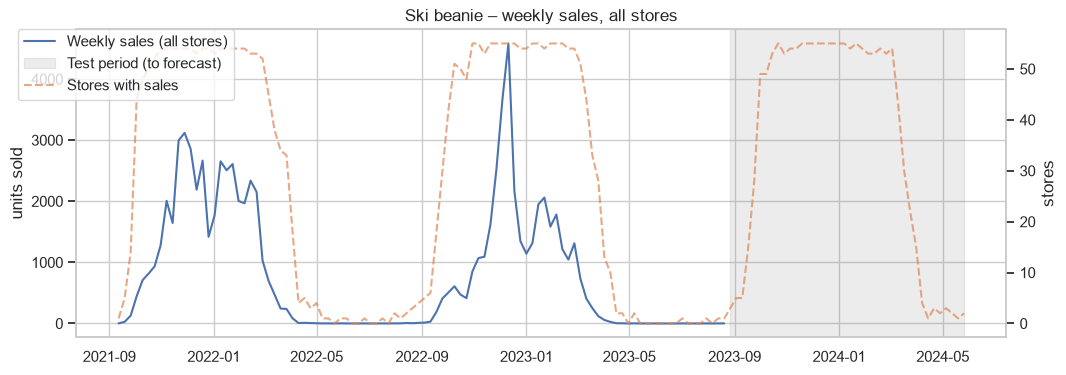

In [5]:
w = weekly_total(train, test)
w_tr = w[w.sales.notna()]
print(len(w_tr), 'semaines d\'entraînement,', w.sales.isna().sum(), 'semaines à prévoir')

fig, ax = plt.subplots()
ax.plot(w_tr.index, w_tr.sales, color='C0', label='Weekly sales (all stores)')
ax.axvspan(w.index[w.sales.isna()][0], w.index[-1], color='grey', alpha=.15, label='Test period (to forecast)')
ax2 = ax.twinx()
ax2.plot(w.index, w.n_stores, color='C1', ls='--', alpha=.7, label='Stores with sales')
ax2.set_ylabel('stores'); ax2.grid(False)
ax.set_ylabel('units sold'); ax.set_title('Ski beanie – weekly sales, all stores')
fig.legend(loc='upper left', bbox_to_anchor=(.07, .9)); plt.show()

### 2.1 Comparaison entre saisons (sept. → août)

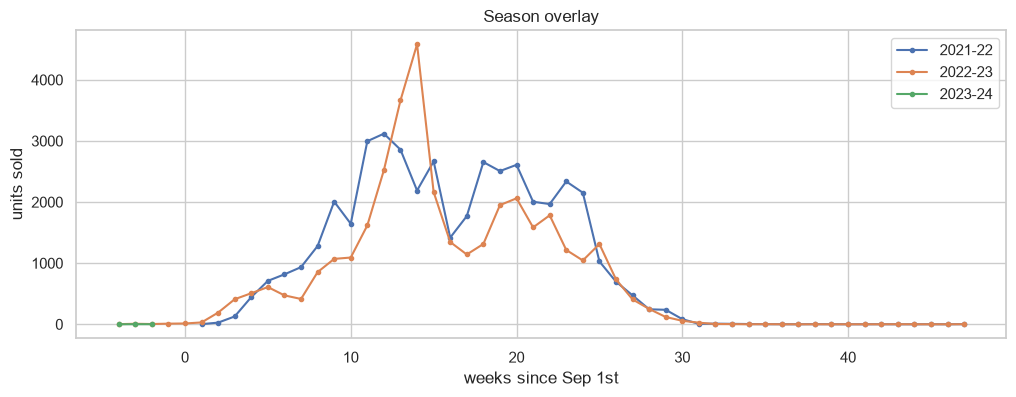

,total,peak,peak_date,weeks
season,,,,
2021-22,44043.0,3119.0,2021-11-28,47
2022-23,36598.0,4582.0,2022-12-11,52


In [6]:
def season_of(d):
    y = d.year if d.month >= 8 else d.year - 1
    return f'{y}-{str(y + 1)[2:]}'

w['season'] = [season_of(d) for d in w.index]
start = {s: g.index.min() for s, g in w.groupby('season')}

# semaine de la saison comptée à partir du 1er septembre (aligne les dates d'une année à l'autre)
w['season_week'] = [((d - pd.Timestamp(year=int(s[:4]), month=9, day=1)).days // 7) for d, s in zip(w.index, w.season)]
w_tr = w[w.sales.notna()]

fig, ax = plt.subplots()
for s, g in w[w.sales.notna()].groupby('season'):
    ax.plot(g.season_week, g.sales, marker='.', label=s)
ax.set_xlabel('weeks since Sep 1st'); ax.set_ylabel('units sold')
ax.set_title('Season overlay'); ax.legend(); plt.show()

# saisons complètes uniquement (les 3 semaines d'août 2023 appartiennent déjà à la saison du test)
summ = w[w.sales.notna() & w.season.isin(['2021-22', '2022-23'])].groupby('season').agg(total=('sales', 'sum'), peak=('sales', 'max'),
                                                 peak_date=('sales', 'idxmax'), weeks=('sales', 'size'))
summ

### 2.2 Saisons de l'année (automne, hiver, printemps, été)

Nous utilisons ici les **saisons astronomiques** (dates approximatives des équinoxes et des solstices) :
automne le 22/09, hiver le 21/12, printemps le 20/03, été le 21/06.

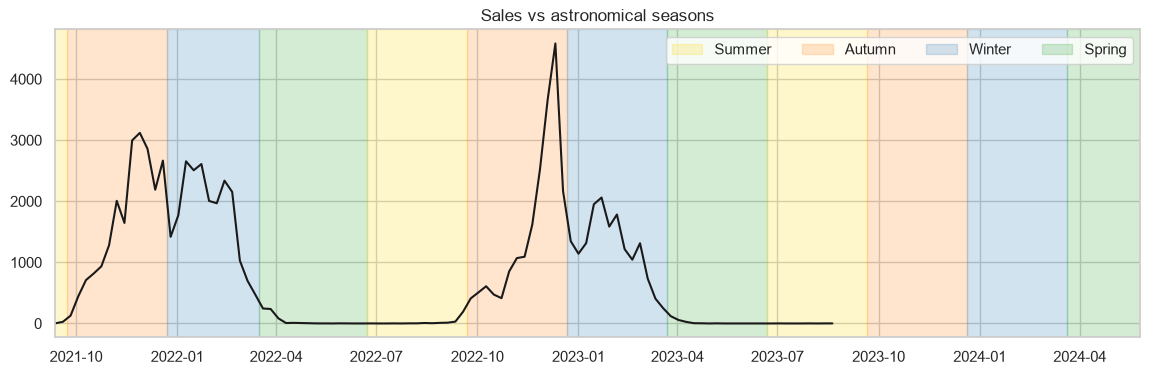

% of season sales,Autumn,Winter,Spring,Summer
season,,,,
2021-22,49.5,49.1,1.4,0.1
2022-23,54.6,44.1,0.6,0.7


,mean,50%,max
astro,,,
Autumn,1607.0,1186.0,4582.0
Winter,1511.0,1418.0,2654.0
Spring,30.0,2.0,245.0
Summer,12.0,1.0,191.0


In [7]:
def astro_season(d):
    md = (d.month, d.day)
    if (3, 20) <= md < (6, 21):  return 'Spring'
    if (6, 21) <= md < (9, 22):  return 'Summer'
    if (9, 22) <= md < (12, 21): return 'Autumn'
    return 'Winter'

season_colors = {'Autumn': 'tab:orange', 'Winter': 'tab:blue', 'Spring': 'tab:green', 'Summer': 'gold'}
w['astro'] = [astro_season(d) for d in w.index]
w_tr = w[w.sales.notna()]

fig, ax = plt.subplots(figsize=(14, 4))
blocks = (w.astro != w.astro.shift()).cumsum()
seen = set()
for _, g in w.groupby(blocks):
    s_ = g.astro.iloc[0]
    ax.axvspan(g.index[0] - pd.Timedelta(days=3.5), g.index[-1] + pd.Timedelta(days=3.5),
               color=season_colors[s_], alpha=.2, label=s_ if s_ not in seen else None)
    seen.add(s_)
ax.plot(w_tr.index, w_tr.sales, color='k')
ax.set_xlim(w.index[0], w.index[-1]); ax.legend(ncol=4); ax.set_title('Sales vs astronomical seasons')
plt.show()

# Part des ventes de chaque saison commerciale (sept. → août) réalisée dans chaque saison de l'année
share = (w_tr[w_tr.season.isin(['2021-22', '2022-23'])]
         .pivot_table(index='season', columns='astro', values='sales', aggfunc='sum')
         [['Autumn', 'Winter', 'Spring', 'Summer']])
display((share.div(share.sum(axis=1), axis=0) * 100).round(1).rename_axis(columns='% of season sales'))
display(w_tr.groupby('astro').sales.describe()[['mean', '50%', 'max']].loc[['Autumn', 'Winter', 'Spring', 'Summer']].round(0))

On constate que c'est généralement en automne que se produit le principal pic de ventes. Comme cette saison précède l'hiver, on peut l'attribuer à la préparation des consommateurs à la saison froide. Ce graphique est intéressant, mais peu efficace pour identifier précisément le pic de ventes, car ses intervalles sont trop larges.

### 2.3 Jours fériés et vacances scolaires (zone C – Paris)

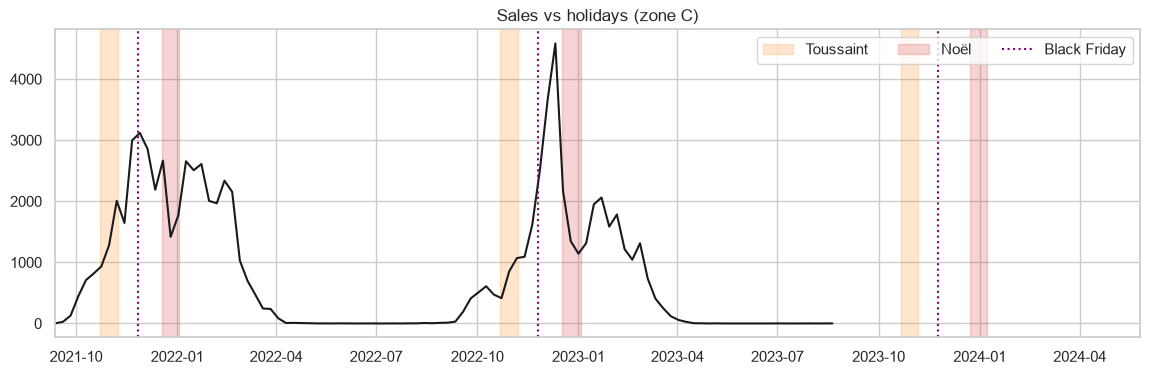

In [8]:
# Vacances scolaires zone C et Black Friday (dates officielles)
holidays = {
    'Toussaint': [('2021-10-23', '2021-11-08'), ('2022-10-22', '2022-11-07'), ('2023-10-21', '2023-11-06')],
    'Noël':      [('2021-12-18', '2022-01-03'), ('2022-12-17', '2023-01-03'), ('2023-12-23', '2024-01-08')],
    # 'Hiver':     [('2022-02-19', '2022-03-07'), ('2023-02-18', '2023-03-06'), ('2024-02-10', '2024-02-26')],
    # 'Printemps': [('2022-04-23', '2022-05-09'), ('2023-04-22', '2023-05-09'), ('2024-04-20', '2024-05-06')],
}
black_friday = ['2021-11-26', '2022-11-25', '2023-11-24']
colors = dict(zip(holidays, ['tab:orange', 'tab:red', 'tab:blue', 'tab:green']))

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(w_tr.index, w_tr.sales, color='k')
for name, spans in holidays.items():
    for i, (a, b) in enumerate(spans):
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=colors[name], alpha=.2, label=name if i == 0 else None)
for i, d in enumerate(black_friday):
    ax.axvline(pd.Timestamp(d), color='purple', ls=':', label='Black Friday' if i == 0 else None)
ax.set_xlim(w.index[0], w.index[-1]); ax.legend(ncol=6); ax.set_title('Sales vs holidays (zone C)')
plt.show()

Le graphique ci-dessus montre une relation claire entre le pic des ventes, ou du moins sa phase de hausse, et la période comprise entre les vacances de la Toussaint et celles de Noël. Le Black Friday semble jouer un rôle d’accélérateur : en 2021, le pic a lieu la semaine même du Black Friday ; en 2022, il marque le début de la forte hausse, le pic étant atteint deux semaines plus tard, juste avant les vacances de Noël.

### 2.4 Saisonnalité mensuelle

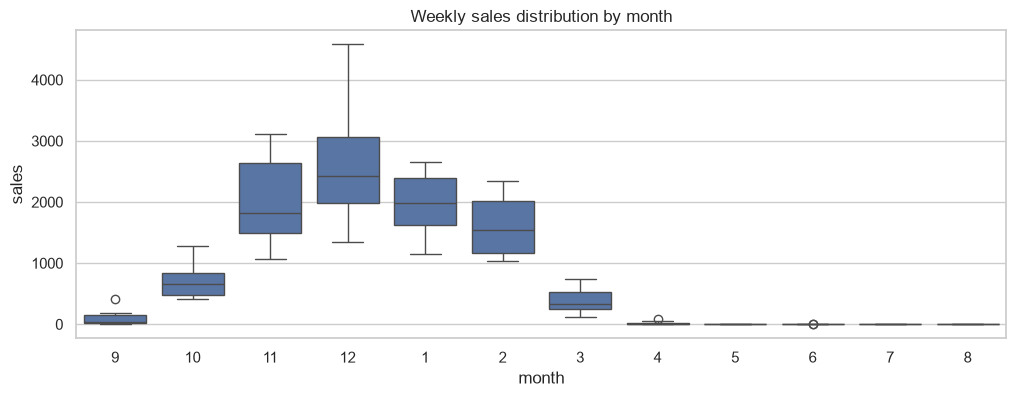

In [9]:
m = w_tr.copy()
m['month'] = m.index.month
order = [9, 10, 11, 12, 1, 2, 3, 4, 5, 6, 7, 8]

sns.boxplot(data=m, x='month', y='sales', order=order)
plt.title('Weekly sales distribution by month'); plt.show()

Le graphique confirme une saisonnalité très marquée et montre que novembre, décembre et janvier concentrent les ventes. La forte dispersion de décembre indique que le niveau du pic varie beaucoup d’une année à l’autre : c’est la période la plus difficile à prévoir et celle qui pèsera le plus dans la MSE.

## 3. Analyse par magasin

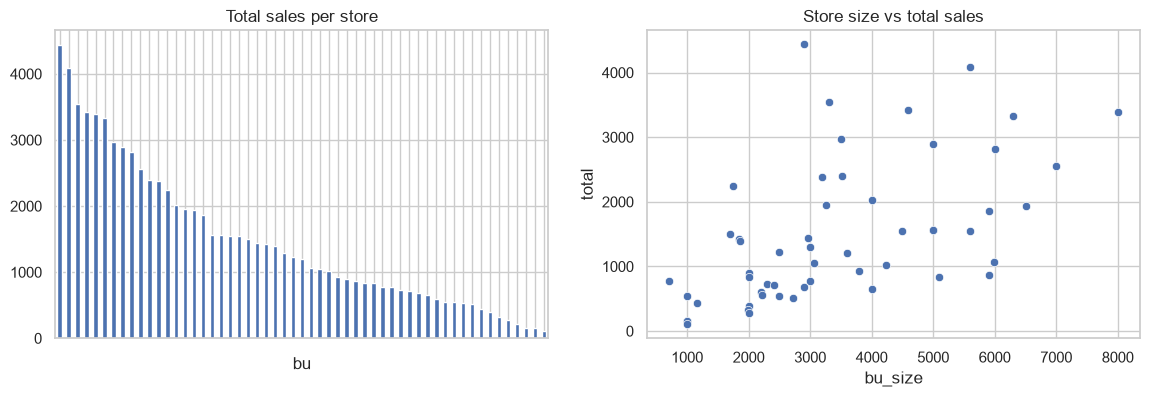

Corr bu_size × total: 0.56
Top 5 magasins = 23% des ventes


,total,bu_size,weeks,city
bu,,,,
426,4438,2900,63,GENNEVILLIERS
539,4089,5600,56,Paris La Défense
189,3550,3300,55,PARIS
1375,3425,4583,54,PARIS
11,3390,8000,63,HERBLAY
243,3335,6300,55,MONTREUIL
429,2966,3508,59,PARIS
186,2899,5000,61,GROSLAY
82,2813,6000,54,CLAYE SOUILLY


In [10]:
per_store = train.groupby('bu').agg(total=('sales_quantity', 'sum'), bu_size=('bu_size', 'first'),
                                    weeks=('week_id', 'size')).sort_values('total', ascending=False)
per_store = per_store.join(stores.set_index('bu'))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
per_store.total.plot.bar(ax=axes[0], color='C0'); axes[0].set_title('Total sales per store'); axes[0].set_xticklabels([])
sns.scatterplot(data=per_store[per_store.bu_size > 1], x='bu_size', y='total', ax=axes[1])
axes[1].set_title('Store size vs total sales'); plt.show()
print('Corr bu_size × total:', per_store[per_store.bu_size > 1][['bu_size', 'total']].corr().iloc[0, 1].round(2))
print('Top 5 magasins = {:.0%} des ventes'.format(per_store.total.head(5).sum() / per_store.total.sum()))
per_store.head(10)

Le premier graphique présente le total des ventes de chaque magasin, par ordre décroissant (du magasin qui a le plus vendu à celui qui a le moins vendu) ; les étiquettes de l'axe des x ont été supprimées pour plus de lisibilité. Le graphique de droite cherche une tendance entre la taille du magasin et le total des ventes, mais la forte dispersion des points rend difficile le tracé d'une droite de corrélation.

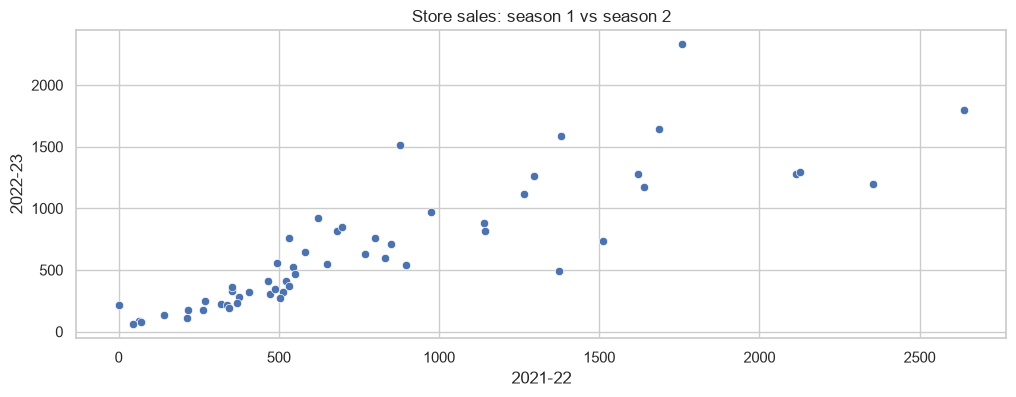

Corr. entre saisons (par magasin) : 0.85
Ratio saison 2 / saison 1 (total) : 0.83


In [11]:
# Les magasins performants sur une saison le restent-ils la saison suivante ?
train['season'] = [season_of(d) for d in train.date]
train = train[train.season.isin(['2021-22', '2022-23'])]
ps = train.pivot_table(index='bu', columns='season', values='sales_quantity', aggfunc='sum').fillna(0)
sns.scatterplot(data=ps, x=ps.columns[0], y=ps.columns[1])
plt.title('Store sales: season 1 vs season 2'); plt.show()
print('Corr. entre saisons (par magasin) :', ps.corr().iloc[0, 1].round(2))
print('Ratio saison 2 / saison 1 (total) :', (ps.iloc[:, 1].sum() / ps.iloc[:, 0].sum()).round(2))

Ce graphique montre une tendance plus nette : les magasins qui ont bien vendu la première année conservent ce comportement l'année suivante.

## 4. Nombre de magasins avec ventes × ventes totales

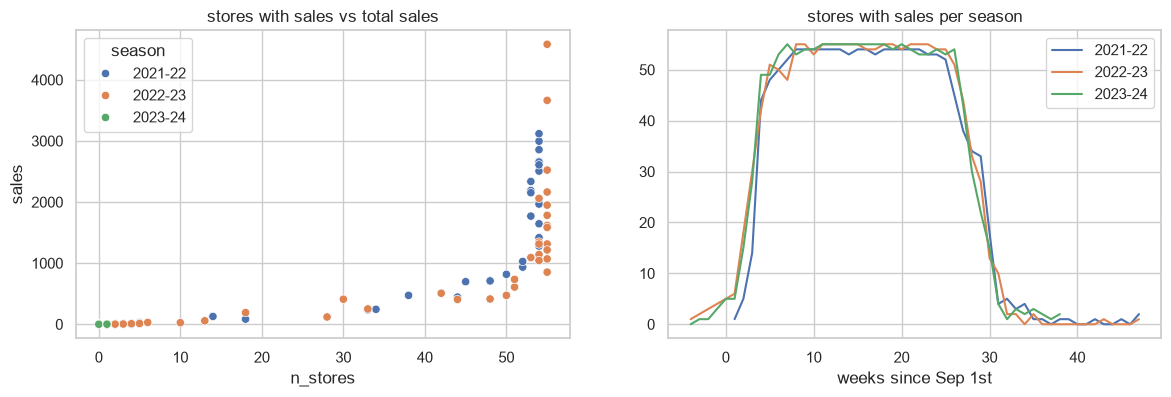

Corr n_stores × sales : 0.8
Corr. en log1p         : 0.987


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.scatterplot(data=w_tr, x='n_stores', y='sales', hue='season', ax=axes[0])
axes[0].set_title('stores with sales vs total sales')
for s, g in w.groupby('season'):
    axes[1].plot(g.season_week, g.n_stores, label=s + (' (test)' if g.sales.isna().all() else ''))
axes[1].set_xlabel('weeks since Sep 1st'); axes[1].set_title('stores with sales per season'); axes[1].legend()
plt.show()
print('Corr n_stores × sales :', w_tr[['n_stores', 'sales']].corr().iloc[0, 1].round(3))
print('Corr. en log1p         :', np.log1p(w_tr[['n_stores', 'sales']]).corr().iloc[0, 1].round(3))

- Le profil de `n_stores` sur la période de test est presque identique à celui des saisons précédentes : il marque très bien
  le début et la fin de la saison (hausse en sept./oct., chute en mars).
- Mais il sature à 55 magasins au milieu de la saison : avec 55 magasins, les ventes varient d'environ 900 à 4 600.
  La forte corrélation (0,98 en log) provient des phases de hausse et de baisse ; **la hauteur du pic doit être expliquée par d'autres
  variables** (calendrier, Black Friday, Noël, historique).

## 5. Stationnarité, ACF et PACF

Nous cherchons maintenant à évaluer dans quelle mesure une méthode classique pourrait prévoir les ventes recherchées.

Une série est stationnaire lorsque son comportement ne change pas dans le temps : la moyenne, la variance et le schéma d'oscillation sont les mêmes sur n'importe quel intervalle.
Comme l'ARIMA suppose que la série est stationnaire, nous devons la transformer (logarithme et différenciation). Nous utilisons ensuite deux tests pour analyser la stationnarité de la série des ventes (ADF et KPSS).

In [13]:
def tests(x, name):
    adf_p = adfuller(x, autolag='AIC')[1]
    kpss_p = kpss(x, regression='c', nlags='auto')[1]
    print(f'{name:<22} ADF p={adf_p:.3f} (H0 : non stationnaire) | KPSS p={kpss_p:.3f} (H0 : stationnaire)')

y = w_tr.sales
tests(y, 'sales')
tests(np.log1p(y), 'log1p(sales)')
tests(np.log1p(y).diff().dropna(), 'diff log1p(sales)')

sales                  ADF p=0.114 (H0 : non stationnaire) | KPSS p=0.100 (H0 : stationnaire)
log1p(sales)           ADF p=0.037 (H0 : non stationnaire) | KPSS p=0.094 (H0 : stationnaire)
diff log1p(sales)      ADF p=0.006 (H0 : non stationnaire) | KPSS p=0.100 (H0 : stationnaire)


C:\Users\debor\AppData\Local\Temp\ipykernel_24580\1226219048.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_p = kpss(x, regression='c', nlags='auto')[1]
C:\Users\debor\AppData\Local\Temp\ipykernel_24580\1226219048.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_p = kpss(x, regression='c', nlags='auto')[1]


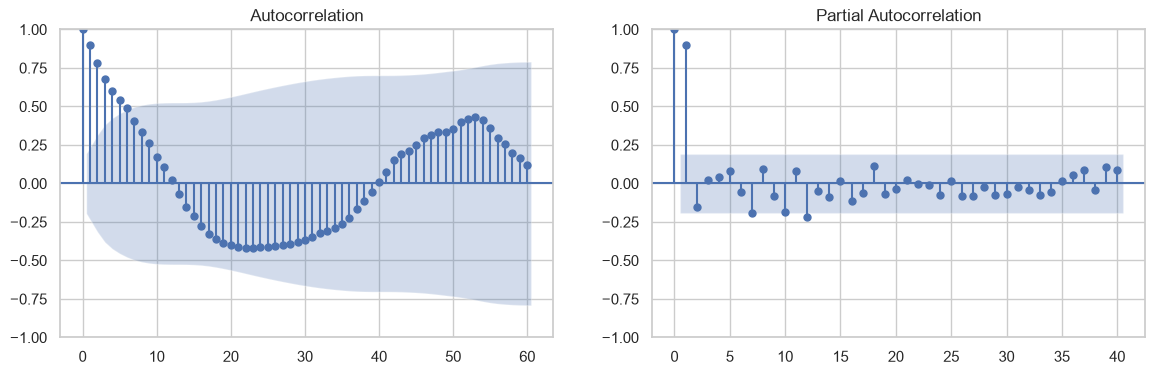

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(y, lags=60, ax=axes[0]); plot_pacf(y, lags=40, ax=axes[1], method='ywm')
plt.show()

- L'ACF décroît lentement, devient négative en été (lags 15–35) puis remonte jusqu'à ≈ 0,42 au lag 52 → **saisonnalité annuelle**.
- ADF/KPSS : la série en log est raisonnablement stationnaire ; la différence du log est clairement stationnaire (d = 1 pour un ARIMA sur le log).
- Une décomposition saisonnière classique (STL / `seasonal_decompose`) de période 52 exige au moins 104 semaines ;
  nous en avons 102. C'est pourquoi nous utilisons la superposition des saisons (section 2.1) à la place de la décomposition.

## 6. Stratégie de validation

Validation : 2022-08-28 → 2023-05-28 | entraînement : 50 semaines


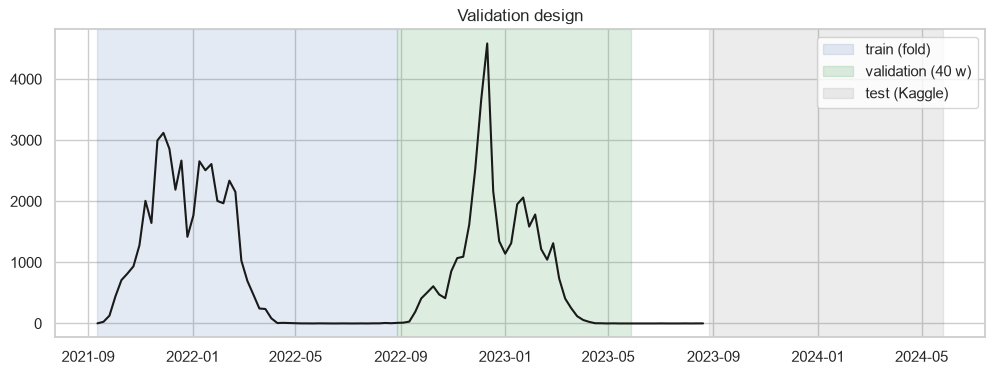

In [15]:
# Fold qui reproduit le test : entraînement jusqu'en août 2022, prévision des 40 semaines suivantes (sept. 2022 → mai 2023)
val_start = pd.Timestamp('2022-08-28')
val_idx = w_tr.loc[val_start:].index[:40]
print('Validation :', val_idx[0].date(), '→', val_idx[-1].date(), '| entraînement :', (w_tr.index < val_start).sum(), 'semaines')

fig, ax = plt.subplots()
ax.plot(w_tr.index, w_tr.sales, color='k')
ax.axvspan(w_tr.index[0], val_start, color='C0', alpha=.15, label='train (fold)')
ax.axvspan(val_idx[0], val_idx[-1], color='C2', alpha=.2, label='validation (40 w)')
ax.axvspan(w.index[w.sales.isna()][0], w.index[-1], color='grey', alpha=.15, label='test (Kaggle)')
ax.legend(); ax.set_title('Validation design'); plt.show()

Pour éviter le future leakage, nous utilisons d’abord 2022 comme entraînement et 2023 comme test. Après l’évaluation des meilleurs modèles, nous utiliserons les deux années comme entraînement pour prédire les données futures.

## 7. Conclusions de l'EDA

1. **Produit très saisonnier :** quasiment aucune vente entre avril et août, pic entre fin novembre et janvier, traîne jusqu'en mars.
2. **Seulement 2 saisons d'historique** → les modèles avec beaucoup de paramètres (SARIMA avec s = 52, LSTM, TFT) disposeront de peu
   d'information ; les baselines saisonnières et les modèles avec covariables devraient être performants.
3. **Pics liés au calendrier :** Black Friday / début décembre et Noël.
   D'après les saisons astronomiques, les ventes se répartissent presque uniquement entre l'**automne et l'hiver** ; le printemps correspond
   à la traîne (mars) et l'été est quasiment nul.
4. **`n_stores` (magasins avec ventes dans la semaine) est connu sur la période de test** : il définit bien le début et la fin de la saison
   (corr. 0,98 en log), mais il sature à 55 au cœur de l'hiver et n'explique pas la hauteur du pic.
5. Les magasins conservent le même ordre de grandeur d'une saison à l'autre → modéliser par magasin puis agréger est une option.
6. **Validation :** un fold qui reproduit le test (entraînement jusqu'en août 2022, prévision de sept. 2022 à mai 2023) + MSE.
   Point faible : ce fold n'est entraîné que sur une seule saison.